# Control application: decentralized online covariance estimation in a sensor network

Code for the control application in the last paragraph of Section IV of *Curvature-Independent Regret Bounds for
Distributed Online Optimization on Hadamard Manifolds* (Z. Cai, E. Sahinoglu, S. Shahrampour): decentralized online
sensor-noise covariance estimation on the SPD manifold with faulty sensors. Its figure appears in our response to
the reviewers (Fig. R1).

Ten sensors on a random geometric graph estimate a measurement-noise covariance on $\mathrm{SPD}(5)$ with the
affine-invariant metric (sectional curvature in $[-1/2,0]$; the baselines use $\kappa=1/2$). In every round,
sensor $i$ forms the sample covariance $S_{i,t}$ of $m=20$ Gaussian measurements with covariance $\Sigma_i$
(heterogeneous around an unknown $\Sigma_0$); two faulty sensors report it multiplied by 4. The feasible set is
the geodesic ball of radius 5 around the nominal covariance $I$, which the algorithm knows; $\Sigma_0$ and
$\Sigma_i$ are used only to generate data.

Local losses: $d(\Sigma,S_{i,t})$ (geometric median: h-convex, robust to faulty sensors, Theorem 3.2) and
$\tfrac12 d^2(\Sigma,S_{i,t})$ (Fréchet mean: 1-strongly h-convex, Theorem 3.4). Methods: D-ROGD; DPRGD and iDPRGD
of Chen and Sun [12] with their prescribed parameters; iDPRGD with a tuned consensus step; the method of [14]
(strongly convex case); reference numbers follow the paper. The figure shows the regret and, for D-ROGD, the
distance of the agents to the estimate obtained without the faulty sensors (median vs. mean).

**How to run.** Run all cells. Every task writes its own file under `results/sensor_network/` and is skipped if
that file exists, so with the results shipped in this repository the notebook only redraws the figure. To rerun
the experiment, delete or rename `results/sensor_network/` first (about 15 minutes on 4 CPU cores). Section 5 needs
only numpy, scipy, matplotlib and `results/sensor_network/`.

**Outputs.** `results/sensor_network/` (one file per task), `figures/fig_control_application.{pdf,png}` and
`figures/summary_sensor_network.txt`. The stored outputs of Sections 1-3 are those of the original run (Kaggle,
numpy 2.1.3, 4 cores); the outputs of Section 5 were regenerated from the saved results.

In [ ]:
import os
for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '1')        # one BLAS thread per worker process

import glob, json, time, types, zipfile
import multiprocessing as mp
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

QUICK_RUN = False                     # True: 3 seeds and short horizons (smoke test)
JOBS = os.cpu_count() or 1            # worker processes (one task per (kappa, seed))
print('numpy', np.__version__, '| cores:', JOBS)

numpy 2.1.3 | cores: 4


## 1. Library

In [ ]:
"""Manifolds used in the experiments.

* Euclidean(d)           : R^d (the kappa = 0 reference).
* Hyperboloid(d, kappa)  : hyperbolic space of curvature -kappa, Lorentz model.
* SPD(p)                 : symmetric positive-definite matrices, affine-invariant
                           metric <U,V>_X = tr(X^-1 U X^-1 V); curvature in [-1/2, 0].

Every method broadcasts over leading dimensions.  ``pdim`` is the number of
trailing axes that index a single point (1 for vectors, 2 for matrices).

Why the Lorentz model: with the diameter of X fixed, raising the curvature pushes
points towards the boundary of the Poincare ball, where float64 loses accuracy
(the README of the first version of this repository, tag v1.0-submission, reports that D = 4 could not be attained
beyond sqrt(kappa) D = 16).  In the Lorentz model distances are computed from the
Lorentzian chord length, which stays accurate, and the time coordinate is
recomputed from the space coordinates after every operation, so iterates never
drift off the manifold.  Distances do not depend on the model, so results are
directly comparable with the original Poincare-ball implementation.
"""

_TINY = 1e-300

class SPD:
    """SPD(p) with the affine-invariant metric (sectional curvature in [-1/2, 0])."""

    pdim = 2

    def __init__(self, p, kappa=0.5):
        self.p = int(p)
        self.d = self.p * (self.p + 1) // 2
        self.kappa = float(kappa)
        self._iu = np.triu_indices(self.p)

    def _s(self, a):
        a = np.asarray(a, float)
        return a.reshape(a.shape + (1, 1))

    @staticmethod
    def _sym(A):
        return 0.5 * (A + np.swapaxes(A, -1, -2))

    @staticmethod
    def _fun(A, f):
        w, V = np.linalg.eigh(A)
        return (V * f(w)[..., None, :]) @ np.swapaxes(V, -1, -2)

    @staticmethod
    def _roots(X):
        w, V = np.linalg.eigh(X)
        s = np.sqrt(w)
        Vt = np.swapaxes(V, -1, -2)
        return (V * s[..., None, :]) @ Vt, (V * (1.0 / s)[..., None, :]) @ Vt

    def origin(self):
        return np.eye(self.p)

    def sym_from_coords(self, w):
        """Symmetric matrix with coordinates w in a Frobenius-orthonormal basis of Sym(p)."""
        w = np.asarray(w, float)
        i, j = self._iu
        sc = np.where(i == j, 1.0, 1.0 / np.sqrt(2.0))
        A = np.zeros(w.shape[:-1] + (self.p, self.p))
        A[..., i, j] = w * sc
        A[..., j, i] = w * sc
        return A

    def exp_origin(self, W):
        return self._fun(self._sym(np.asarray(W, float)), np.exp)

    def transport_from_origin(self, A, W):
        """Parallel transport from I to A of the tangent vector W (= A^1/2 W A^1/2)."""
        Ah, _ = self._roots(A)
        return Ah @ W @ Ah

    def dist_origin(self, X):
        w = np.linalg.eigvalsh(self._sym(X))
        return np.sqrt(np.sum(np.log(w) ** 2, -1))

    # Square roots are computed on X before broadcasting, so pairwise calls such as
    # logd(Z[:, None], Y[None, :]) need n (not n^2) extra eigendecompositions.
    def logd(self, X, Y):
        Xh, Xih = self._roots(X)
        w, V = np.linalg.eigh(self._sym(Xih @ Y @ Xih))
        lw = np.log(w)
        Lw = (V * lw[..., None, :]) @ np.swapaxes(V, -1, -2)
        return Xh @ Lw @ Xh, np.sqrt(np.sum(lw * lw, -1))

    def log(self, X, Y):
        return self.logd(X, Y)[0]

    def dist(self, X, Y):
        _, Xih = self._roots(X)
        w = np.linalg.eigvalsh(self._sym(Xih @ Y @ Xih))
        return np.sqrt(np.sum(np.log(w) ** 2, -1))

    def exp(self, X, V):
        Xh, Xih = self._roots(X)
        return self._sym(Xh @ self._fun(self._sym(Xih @ V @ Xih), np.exp) @ Xh)

    def geodesic(self, X, Y, f):
        """X^1/2 (X^-1/2 Y X^-1/2)^f X^1/2: point at fraction f of the geodesic."""
        f = np.asarray(f, float)
        Xh, Xih = self._roots(X)
        w, V = np.linalg.eigh(self._sym(Xih @ Y @ Xih))
        P = (V * (w ** f[..., None])[..., None, :]) @ np.swapaxes(V, -1, -2)
        return self._sym(Xh @ P @ Xh)

    def norm(self, X, V):
        _, Xih = self._roots(X)
        Mw = Xih @ V @ Xih
        return np.sqrt(np.sum(Mw * Mw, axis=(-2, -1)))

    def inner(self, X, U, V):
        _, Xih = self._roots(X)
        return np.sum((Xih @ U @ Xih) * (Xih @ V @ Xih), axis=(-2, -1))

    def proj_ball(self, Z, R):
        """Metric projection onto the closed geodesic ball of radius R around I."""
        L = self._fun(self._sym(Z), np.log)
        d = np.sqrt(np.sum(L * L, axis=(-2, -1)))
        f = np.where(d > R, R / np.maximum(d, _TINY), 1.0)
        return self._fun(L * f[..., None, None], np.exp)

In [ ]:
"""Communication graphs and Metropolis weights.

Metropolis rule: w_ij = 1 / (1 + max(deg_i, deg_j)) for neighbours i != j and
w_ii = 1 - sum_{j != i} w_ij.  The resulting W is symmetric and doubly
stochastic, and each agent only needs its own degree and its neighbours' degrees.
"""


def is_connected(A):
    n = A.shape[0]
    seen = np.zeros(n, bool)
    stack = [0]
    seen[0] = True
    while stack:
        i = stack.pop()
        for j in np.nonzero(A[i])[0]:
            if not seen[j]:
                seen[j] = True
                stack.append(j)
    return bool(seen.all())


def circulant(n, k):
    """Ring in which every agent is linked to its k nearest neighbours on each side."""
    A = np.zeros((n, n), int)
    for i in range(n):
        for s in range(1, k + 1):
            A[i, (i + s) % n] = A[(i + s) % n, i] = 1
    return A


def complete(n):
    return np.ones((n, n), int) - np.eye(n, dtype=int)


def path(n):
    A = np.zeros((n, n), int)
    for i in range(n - 1):
        A[i, i + 1] = A[i + 1, i] = 1
    return A


def erdos_renyi(n, p, seed=0):
    rng = np.random.default_rng(seed)
    while True:
        U = np.triu(rng.random((n, n)) < p, 1)
        A = (U | U.T).astype(int)
        if is_connected(A):
            return A


def random_geometric(n, radius, seed=0):
    """Random geometric graph on [0,1]^2 (standard sensor-network model)."""
    rng = np.random.default_rng(seed)
    while True:
        P = rng.random((n, 2))
        Dm = np.linalg.norm(P[:, None] - P[None], axis=-1)
        A = ((Dm < radius) & ~np.eye(n, dtype=bool)).astype(int)
        if is_connected(A):
            return A


def metropolis(A):
    A = np.asarray(A, int)
    n = A.shape[0]
    deg = A.sum(1)
    W = np.zeros((n, n))
    I, J = np.nonzero(A)
    W[I, J] = 1.0 / (1.0 + np.maximum(deg[I], deg[J]))
    W[np.arange(n), np.arange(n)] = 1.0 - W.sum(1)
    return W


def sigma2(W):
    """Second-largest singular value; for symmetric W equals max(|lambda_2|, |lambda_n|)."""
    s = np.sort(np.abs(np.linalg.eigvalsh(W)))[::-1]
    return float(s[1])


def make_graph(name, n, seed=0, radius=0.5):
    """'ring' (2 neighbours), 'knn4' (4 nearest neighbours, the network of [12]),
    'complete', 'path', 'er' (p = 0.5), 'rgg' (random geometric graph with the given radius)."""
    if name == 'ring':
        A = circulant(n, 1)
    elif name == 'knn4':
        A = circulant(n, 2)
    elif name == 'complete':
        A = complete(n)
    elif name == 'path':
        A = path(n)
    elif name == 'er':
        A = erdos_renyi(n, 0.5, seed)
    elif name == 'rgg':
        A = random_geometric(n, radius, seed)
    else:
        raise ValueError(name)
    W = metropolis(A)
    return W, sigma2(W)

In [ ]:
"""Curvature constants, baseline parameters and regret bounds.

All curvature-dependent parameters used anywhere in the experiments are computed
here, so that their values can be listed in the response letter.

References (numbering of the paper):
[12] Chen & Sun, Decentralized online Riemannian optimization with dynamic
     environments (DPRGD, iDPRGD).
[14] Cai, Sahinoglu & Shahrampour, Decentralized online Riemannian optimization
     for strongly geodesically convex functions.
"""


def zeta(kappa, c):
    """zeta(kappa, c) = sqrt(kappa) c coth(sqrt(kappa) c), with zeta = 1 for kappa c = 0."""
    x = np.sqrt(kappa) * c
    return 1.0 if x == 0 else float(x / np.tanh(x))


# ------------------------------------------------------------- baselines of [12]
def dprgd_cor7(D, L, kappa, sigma, n, T):
    """Constant step of DPRGD from [12, Cor. 7] with P_T = 0:
    eta = D / sqrt(T C'),  C' = L^2 zeta(kappa, D + L) + 2 sigma sqrt(n) L^2 / (1 - sigma)."""
    Cp = L ** 2 * zeta(kappa, D + L) + 2.0 * sigma * np.sqrt(n) * L ** 2 / (1.0 - sigma)
    return min(1.0, D / np.sqrt(T * Cp))


def idprgd_cor12(D, L, kappa, sigma, n, T):
    """iDPRGD of [12]: consensus step gamma = 1/(2 C3), C3 = zeta(kappa, 2D) (Lemma 8),
    and constant step eta = D / sqrt(2 C4 T) (Cor. 12, P_T = 0) with
    C4 = 8 C3 sqrt(n) L^2 / (1 - sigma) + zeta(kappa, 2D + L) L^2 / 2."""
    C3 = zeta(kappa, 2 * D)
    C4 = 8.0 * C3 * np.sqrt(n) * L ** 2 / (1.0 - sigma) + zeta(kappa, 2 * D + L) * L ** 2 / 2.0
    return min(1.0, D / np.sqrt(2.0 * C4 * T)), 1.0 / (2.0 * C3)


# ---------------------------------------------------------------- baseline of [14]
def cai12(D, L, kappa, mu, T):
    """[14] on a Hadamard manifold: consensus step s = C2/(2 C1) with C1 = zeta(kappa, D),
    C2 = 1, and gradient steps eta_t = 1/(mu t + L/D)."""
    t = np.arange(1, T + 1)
    return 1.0 / (mu * t + L / D), 1.0 / (2.0 * zeta(kappa, D))


# ------------------------------------------------------- bounds of the revised paper
def bound_hconvex(eta, L, D, sigma):
    """Theorem 3.2 for a nonincreasing schedule eta[0..T-1]:
    2 L^2 sigma/(1-sigma) sum_{t<T} eta_t + L^2/2 sum_t eta_t + D^2/(2 eta_T)."""
    eta = np.asarray(eta, float)
    return (2.0 * L ** 2 * sigma / (1.0 - sigma) * eta[:-1].sum()
            + 0.5 * L ** 2 * eta.sum() + D ** 2 / (2.0 * eta[-1]))


def bound_strong(L, mu, sigma, T):
    """Theorem 3.4 with eta_t = 1/(mu t): (2 L^2 sigma/(1-sigma) + L^2/2)(1 + log T)/mu."""
    return (2.0 * L ** 2 * sigma / (1.0 - sigma) + 0.5 * L ** 2) * (1.0 + np.log(T)) / mu


def inexact_extra(eps, eta, L, D, sigma):
    """Additional term E_T of Proposition 3.6 for consensus errors eps[0..T-1].

    The eps^2/2 term, absent from (22), also covers consensus outputs outside X;
    it is negligible for the tolerances used here."""
    eps = np.asarray(eps, float)
    eta = np.asarray(eta, float)
    return 2.0 * L / (1.0 - sigma) * eps[:-1].sum() + np.sum((D * eps + 0.5 * eps ** 2) / eta)

In [ ]:
"""Consensus solvers, comparators and diagnostics.

Consensus (line 6 of Algorithm 1).  Agent i computes
    x_i = argmin_z F_i(z),   F_i(z) = 1/2 sum_j W_ij d^2(z, y_j),
by Riemannian gradient descent started at its own point y_i.  F_i is 1-strongly
g-convex on a Hadamard manifold, hence
    d(z, x_i^e) <= ||grad F_i(z)||,
so stopping when ||grad F_i|| <= eps returns a point within distance eps of the
exact weighted Frechet mean: eps is exactly the eps_t of Proposition 3.6.  Steps
start at 1 (= Karcher iteration) and are halved until an Armijo condition holds;
no curvature information is needed.

The closed-form consensus of [12] (eq. (7)) and [14] (step (II)),
    x_i = Exp_{y_i}(gamma sum_j W_ij Log_{y_i}(y_j)),
is one gradient step on the same F_i with step gamma started at y_i, so both
consensus types share the same code path.
"""


def _contract(W, L):
    """G_i = sum_j W_ij L_ij for L of shape (n, n, *point)."""
    return np.einsum('ij,ij...->i...', W, L)


def _scale(a, X, pdim):
    a = np.asarray(a, float)
    return a.reshape(a.shape + (1,) * pdim) * X


def fm_consensus(M, Y, W, tol=1e-9, max_iter=2000, c=0.25, max_halvings=60, stall=50):
    """Weighted Frechet means of all agents to accuracy tol (distance).

    Riemannian gradient descent on F_i from y_i with Armijo backtracking.  The first
    trial step of each iteration is min(1, 2 a_prev), where a_prev is the step
    accepted in the previous iteration: the solver learns a step of order
    1/zeta(kappa, r), r being the spread of the averaged points, without being told
    the curvature.  When the points are close (the usual case after the first rounds),
    the unit step, i.e. the Karcher iteration, is accepted at every iteration.

    If the gradient norm of an agent has not improved by 1% over `stall` accepted
    iterations, the agent stops: its accuracy has reached the float64 floor, which
    only happens when the averaged points are very far apart at large curvature
    (e.g. sqrt(kappa) x spread = 16 in the first round).  The returned gradient norm
    is then the attained accuracy, covered by Proposition 3.6.

    Returns (Z, iters, evals, gnorm): solution, accepted steps per agent, number of
    objective/gradient evaluations per agent, final gradient norms."""
    n = W.shape[0]
    pd = M.pdim
    Z = Y.copy()
    L, Dd = M.logd(Z[:, None], Y[None, :])
    G = _contract(W, L)                      # = -grad F_i
    g = M.norm(Z, G)
    F = 0.5 * np.sum(W * Dd ** 2, 1)
    a_prev = np.full(n, 0.5)
    iters = np.zeros(n, int)
    evals = np.ones(n, int)
    best = g.copy()
    since = np.zeros(n, int)
    done = np.zeros(n, bool)
    for _ in range(max_iter):
        act = np.nonzero((g > tol) & ~done)[0]
        if act.size == 0:
            break
        alpha = np.minimum(1.0, 2.0 * a_prev[act])
        pend = np.arange(act.size)
        for _ in range(max_halvings):
            ids = act[pend]
            cand = M.exp(Z[ids], _scale(alpha[pend], G[ids], pd))
            Lc, Dc = M.logd(cand[:, None], Y[None, :])
            Gc = _contract(W[ids], Lc)
            gc = M.norm(cand, Gc)
            Fc = 0.5 * np.sum(W[ids] * Dc ** 2, 1)
            evals[ids] += 1
            armijo = Fc <= F[ids] - c * alpha[pend] * g[ids] ** 2
            # Below round-off the Armijo test is meaningless; accept if the gradient shrinks.
            flat = np.abs(Fc - F[ids]) <= 1e-12 * np.maximum(1.0, F[ids])
            ok = armijo | (flat & (gc < g[ids]))
            acc = ids[ok]
            Z[acc], G[acc], g[acc], F[acc] = cand[ok], Gc[ok], gc[ok], Fc[ok]
            a_prev[acc] = alpha[pend][ok]
            iters[acc] += 1
            imp = gc[ok] < 0.99 * best[acc]
            best[acc] = np.where(imp, gc[ok], best[acc])
            since[acc] = np.where(imp, 0, since[acc] + 1)
            done[acc] |= since[acc] >= stall
            pend = pend[~ok]
            alpha[pend] *= 0.5
            if pend.size == 0:
                break
        else:  # no acceptable step (numerical floor): stop these agents
            done[act[pend]] = True
    return Z, iters, evals, g


def cf_consensus(M, Y, W, gamma):
    """Closed-form consensus x_i = Exp_{y_i}(gamma sum_j W_ij Log_{y_i} y_j)."""
    L, _ = M.logd(Y[:, None], Y[None, :])
    return M.exp(Y, gamma * _contract(W, L))


# ------------------------------------------------------------------ batch problems
def batch_frechet_mean(M, P, z0, tol=1e-10, max_iter=3000, c=0.25, stall=50):
    """argmin_z 1/(2N) sum_k d^2(z, P_k): RGD with Armijo backtracking, the same step
    memory as fm_consensus, and a stall test (float64 floor for very spread data)."""
    z = np.array(z0, float)

    def evaluate(z):
        L, d = M.logd(z[None], P)
        G = L.mean(0)
        return G, M.norm(z, G), 0.5 * np.mean(d ** 2)

    G, g, F = evaluate(z)
    a_prev, best, since = 0.5, g, 0
    for _ in range(max_iter):
        if g <= tol or since >= stall:
            break
        a = min(1.0, 2.0 * a_prev)
        for _ in range(60):
            zc = M.exp(z, a * G)
            Gc, gc, Fc = evaluate(zc)
            if Fc <= F - c * a * g * g or (abs(Fc - F) <= 1e-13 * max(1.0, F) and gc < g):
                z, G, g, F, a_prev = zc, Gc, gc, Fc, a
                since = 0 if g < 0.99 * best else since + 1
                best = min(best, g)
                break
            a *= 0.5
        else:
            break
    return z, g


def batch_geometric_median(M, P, z0, tol=1e-10, max_iter=3000, stall=50):
    """argmin_z 1/N sum_k d(z, P_k) by a monotone Riemannian Weiszfeld iteration."""
    z = np.array(z0, float)

    def evaluate(z):
        L, d = M.logd(z[None], P)
        keep = d > 1e-14
        inv = np.where(keep, 1.0 / np.maximum(d, 1e-300), 0.0)
        v = np.tensordot(inv, L, axes=(0, 0)) / inv.sum()   # Weiszfeld step
        return v, M.norm(z, v), np.mean(d)

    v, s, F = evaluate(z)
    best, since = s, 0
    for _ in range(max_iter):
        if s <= tol or since >= stall:
            break
        a = 1.0
        for _ in range(60):
            zc = M.exp(z, a * v)
            vc, sc, Fc = evaluate(zc)
            if Fc < F or (abs(Fc - F) <= 1e-13 * max(1.0, F) and sc < s):
                z, v, s, F = zc, vc, sc, Fc
                since = 0 if s < 0.99 * best else since + 1
                best = min(best, s)
                break
            a *= 0.5
        else:
            break
    return z, s


def log_checkpoints(T, K=30, t_min=10):
    """About K log-spaced horizons in [t_min, T], always including T."""
    ck = np.unique(np.round(np.geomspace(t_min, T, K)).astype(int))
    return ck if ck[-1] == T else np.append(ck, T)


def loss_values(loss, d):
    return d if loss == 'median' else 0.5 * d ** 2


def prefix_comparators(M, S, loss, checkpoints, R):
    """Static regret comparators for every horizon t_k in checkpoints.

    For horizon t the comparator is x*_t = argmin_{x in X} sum_{s<=t} f_s(x), i.e.
    the geometric median / Frechet mean of all n t observations; the function
    returns B[k] = sum_{s<=t_k} f_s(x*_{t_k}), so that Reg(t_k) = A(t_k) - B[k].
    The data lie in the convex set X, hence so does x*_t (checked)."""
    T, n = S.shape[:2]
    P = S.reshape((T * n,) + S.shape[2:])
    z = M.origin()
    B, Z, worst = [], [], 0.0
    solve = batch_geometric_median if loss == 'median' else batch_frechet_mean
    for tk in checkpoints:
        pts = P[: tk * n]
        z, _ = solve(M, pts, z)
        worst = max(worst, float(M.dist_origin(z)) - R)
        B.append(loss_values(loss, M.dist(z[None], pts)).sum() / n)
        Z.append(z.copy())
    if worst > 1e-8:
        print(f"WARNING: comparator outside X by {worst:.2e}; enlarge R")
    return np.array(B), np.array(Z)


def mu_eff(M, z, P):
    """Smallest eigenvalue of the Hessian of 1/(2N) sum_k d^2(., P_k) at z.

    In constant curvature -kappa, Hess 0.5 d^2(., p) has eigenvalue 1 along Log_z p
    and sqrt(kappa) r coth(sqrt(kappa) r) >= 1 in the transverse directions."""
    E = M.frame(z)                                  # (d, ambient) orthonormal basis
    L, r = M.logd(z[None], P)
    keep = r > 1e-12
    U = L[keep] / r[keep, None]
    C = np.array([M.inner(z, U, e) for e in E]).T   # (N, d) coordinates
    phi = M.hess_sqdist_factor(r[keep])
    d = E.shape[0]
    H = (phi[:, None, None] * np.eye(d)[None] + (1.0 - phi)[:, None, None]
         * C[:, :, None] * C[:, None, :]).mean(0)
    return float(np.linalg.eigvalsh(H)[0])

In [ ]:
"""Decentralized online Riemannian gradient methods.

One routine covers every method in the experiments; they differ only in the
step-size sequence and in the consensus step:

  D-ROGD (Algorithm 1)  consensus='fm' : weighted Frechet mean to tolerance tol,
                                          then projection onto X
  DPRGD of [12]         consensus='fm' : same algorithm, step size of [12, Cor. 7]
  iDPRGD of [12]        consensus='cf' : closed-form consensus with step gamma
  method of [14]        consensus='cf' : closed-form consensus with step s

Round t, agent i:  observe S_{i,t};  y_i = P_X(Exp_{x_i}(-eta_t g_i));
                   x_i <- consensus({y_j}).
"""



def _gradient_step(M, X, St, loss, eta):
    """y_i = Exp_{x_i}(-eta g_i) for the local loss l(d(., S_i)); returns (y, |g_i|).

    -g_i points along the geodesic from x_i to S_i (canonical h-subgradient for
    the median, -grad 0.5 d^2 = Log_x S for the mean), so the step is the point at
    fraction eta/d (median) or eta (mean) of that geodesic.  It is evaluated with
    M.geodesic, which is numerically stable at large curvature; a step that
    overshoots S_i (median with eta > d) uses Exp with a unit direction instead."""
    L, d = M.logd(X, St)
    n = d.shape[0]
    if loss == 'mean':
        frac, gnorm = np.full(n, float(eta)), d
    else:
        frac = np.where(d > 0, eta / np.maximum(d, 1e-300), 0.0)
        gnorm = (d > 0).astype(float)
    Y = M.geodesic(X, St, np.minimum(frac, 1.0))
    over = frac > 1.0
    if np.any(over):
        u = L[over] / d[over].reshape((-1,) + (1,) * M.pdim)
        Y[over] = M.exp(X[over], eta * u)
    return Y, gnorm


def run_decentralized(M, S, W, loss, eta, R, x1, consensus='fm', tol=1e-9,
                      gamma=None, project_consensus=None, record=True, track=None):
    """Run one method on the observation stream S (T, n, *point).

    eta : array (T,) of step sizes.   tol : float or array (T,) (D-ROGD only).
    Returns a dict with
      cum_loss   (T,)  A(t) = sum_{s<=t} (1/n) sum_i f_s(x_{i,s})  (f_s = network loss)
      iters      (T,)  mean accepted consensus steps per agent (0 for 'cf': one closed-form step)
      evals      (T,)  mean Log/Exp evaluations of the consensus solver per agent
      t_cons     (T,)  wall-clock time of the consensus step [s]
      disp       (T,)  mean pairwise distance between agents (disagreement)
      spread     (T,)  mean over agents of max_{j,k in N_i} d(y_j, y_k)  (r_t of the cost remark)
      gmax              largest local (sub)gradient norm observed (empirical L)
      track      (T,)  track(X) after every round, if a callable is given
    """
    T, n = S.shape[:2]
    if project_consensus is None:
        project_consensus = consensus == 'fm'
    tol_t = np.broadcast_to(np.asarray(tol, float), (T,))
    X = np.repeat(np.asarray(x1, float)[None], n, 0)
    nb = (W > 0)
    pair_mask = nb[:, :, None] & nb[:, None, :]
    out = {k: np.zeros(T) for k in ('net', 'iters', 'evals', 't_cons', 'disp', 'spread', 'track')}
    gmax = 0.0
    for t in range(T):
        St = S[t]
        # network loss f_t(x_i) = (1/n) sum_j l(d(x_i, S_j)), averaged over agents
        out['net'][t] = loss_values(loss, M.dist(X[:, None], St[None, :])).mean()
        Y, gnorm = _gradient_step(M, X, St, loss, eta[t])
        gmax = max(gmax, float(np.max(gnorm)))
        Y = M.proj_ball(Y, R)
        if record:
            Dy = M.dist(Y[:, None], Y[None, :])
            out['spread'][t] = np.max(np.where(pair_mask, Dy[None], 0.0), axis=(1, 2)).mean()
        t0 = time.perf_counter()
        if consensus == 'fm':
            X, it, ev, _ = fm_consensus(M, Y, W, tol=tol_t[t])
            out['iters'][t], out['evals'][t] = it.mean(), ev.mean()
        elif consensus == 'cf':
            X = cf_consensus(M, Y, W, gamma)
            out['evals'][t] = 1.0
        else:
            raise ValueError(consensus)
        if project_consensus:
            X = M.proj_ball(X, R)
        out['t_cons'][t] = time.perf_counter() - t0
        if record:
            out['disp'][t] = M.dist(X[:, None], X[None, :]).mean()
        if track is not None:
            out['track'][t] = track(X)
    res = {k: v for k, v in out.items() if k != 'net'}
    res['cum_loss'] = np.cumsum(out['net'])
    res['gmax'] = gmax
    res['x_final'] = X
    return res

In [ ]:
"""Observation streams of the two experiments.

Curvature study (fig1_fig2_hyperbolic_curvature.ipynb).  All random numbers are drawn in tangent
coordinates *before* any curvature-dependent map, in the same order for every
kappa, so a given seed produces the same intrinsic data at every curvature
(common random numbers).  What is held fixed across kappa:
  * X = closed geodesic ball of radius R around the origin, so D = 2R;
  * anchors (local data centres) at fixed signed positions on ONE geodesic through
    the origin, so all anchor-to-anchor distances are identical for every kappa
    ('line'); 'random' places them at radius rho_a in random directions, in which
    case their mutual distances grow with kappa (reported, robustness check);
  * observations S = Exp_{a_i}(xi) with xi isotropic in the tangent space at a_i
    (frame transported from the origin) and |xi| ~ U[0, rho_p]: the law of
    d(a_i, S) is the same for every kappa;
  * rho_a + rho_p <= R, so all data lie in X;
  * common initial point on the boundary of X (distance R from the data centre).
'geodesic' puts anchors, observations and the initial point on one geodesic: the
problem is then exactly one-dimensional and the regret must not depend on kappa
(unit test).

Control application (control_application_sensor_network.ipynb): decentralized online
covariance estimation in a sensor network.
Sensor i has true noise covariance Sigma_i = Exp_{Sigma_0}(rho_h U_i); in each
round it forms the sample covariance of m zero-mean Gaussian measurements.  Faulty
sensors report their sample covariance multiplied by `gain`.  X is the geodesic
ball of radius R around the nominal covariance I, which the algorithm knows;
Sigma_0 and Sigma_i are only used to generate data.
"""

def spd_scenario(seed, T, n=10, p=5, m=20, rho0=1.0, rho_h=0.5, n_faulty=2,
                 gain=4.0, R=7.0):
    rng = np.random.default_rng(seed)
    M = SPD(p)

    def unit_sym():
        w = rng.standard_normal(M.d)
        return M.sym_from_coords(w / np.linalg.norm(w))

    Sigma0 = M.exp_origin(rho0 * unit_sym())
    Sig = np.array([M.exp(Sigma0, M.transport_from_origin(Sigma0, rho_h * unit_sym()))
                    for _ in range(n)])
    faulty = np.sort(rng.choice(n, n_faulty, replace=False))
    Lc = np.linalg.cholesky(Sig)                              # (n, p, p)
    Zs = rng.standard_normal((T, n, m, p)) @ np.swapaxes(Lc, -1, -2)[None]
    S = np.swapaxes(Zs, -1, -2) @ Zs / m                       # sample covariances
    S[:, faulty] *= gain
    S = 0.5 * (S + np.swapaxes(S, -1, -2))
    healthy = np.setdiff1d(np.arange(n), faulty)
    info = dict(Sigma0=Sigma0, Sigma=Sig, faulty=faulty, healthy=healthy, R=R, D=2 * R,
                kappa=M.kappa, max_dist=float(M.dist_origin(S).max()))
    return M, S, M.origin(), info

In [ ]:
def bin_series(x, nb=50):
    """Means of x over nb log-spaced blocks of rounds (keeps result files small)."""
    T = len(x)
    edges = np.unique(np.round(np.geomspace(1, T + 1, nb + 1)).astype(int))
    mids = np.sqrt(edges[:-1] * np.maximum(edges[1:] - 1, edges[:-1]))
    vals = np.array([x[a - 1:b - 1].mean() for a, b in zip(edges[:-1], edges[1:])])
    return mids, vals


def ci95(a, axis=0):
    """Mean and half-width of the 95% t-confidence interval."""
    a = np.asarray(a, float)
    k = a.shape[axis]
    if k < 2:
        return a.mean(axis), np.zeros_like(a.mean(axis))
    try:
        from scipy.stats import t as student
        q = student.ppf(0.975, k - 1)
    except ImportError:
        q = 1.96
    return a.mean(axis), q * a.std(axis, ddof=1) / np.sqrt(k)


def run_pool(fn, tasks, jobs):
    """Run tasks (each writes its own result file, so interrupted runs resume)."""
    if jobs <= 1 or 'fork' not in mp.get_all_start_methods():
        for k, t in enumerate(tasks):
            print(f"[{k + 1}/{len(tasks)}] {fn(t)}", flush=True)
        return
    with mp.get_context('fork').Pool(jobs) as pool:   # notebook functions are inherited by fork
        for k, r in enumerate(pool.imap_unordered(fn, tasks)):
            print(f"[{k + 1}/{len(tasks)}] {r}", flush=True)


def save_json(obj, path):
    with open(path, 'w') as f:
        json.dump(obj, f, indent=2, sort_keys=True)


def load_json(path):
    with open(path) as f:
        return json.load(f)

## 2. Sanity checks

In [ ]:
rng = np.random.default_rng(0)


def check(name, ok):
    print(f"[{'ok' if ok else 'FAIL'}] {name}")
    assert ok, name


M = SPD(5)
X = M.exp_origin(M.sym_from_coords(rng.standard_normal((30, M.d))))
Y = M.exp_origin(M.sym_from_coords(rng.standard_normal((30, M.d))))
V = M.log(X, Y)
check("SPD |Log_X Y|_X = d(X,Y)", np.allclose(M.norm(X, V), M.dist(X, Y), atol=1e-9))
check("SPD Exp_X Log_X Y = Y", np.allclose(M.exp(X, V), Y, atol=1e-8))
A_ = rng.standard_normal((5, 5)) + 3 * np.eye(5)
check("SPD affine invariance", np.allclose(M.dist(A_ @ X @ A_.T, A_ @ Y @ A_.T), M.dist(X, Y), atol=1e-8))
f = rng.random(30)
check("SPD geodesic interpolation", np.allclose(M.dist(X, M.geodesic(X, Y, f)), f * M.dist(X, Y), atol=1e-8))
Wg, _ = make_graph('rgg', 10, 0, 0.5)
Yc = M.exp_origin(M.sym_from_coords(rng.standard_normal((10, M.d))))
Z, it, ev, g = fm_consensus(M, Yc, Wg, tol=1e-10)
check("SPD consensus to tolerance", np.all(g <= 1e-10))
L0, _ = M.logd(Yc[:, None], Yc[None])
check("SPD closed form = one Karcher step",
      np.allclose(cf_consensus(M, Yc, Wg, 1.0), M.exp(Yc, np.einsum('ij,ij...->i...', Wg, L0))))
print('all checks passed')

[ok] SPD |Log_X Y|_X = d(X,Y)
[ok] SPD Exp_X Log_X Y = Y
[ok] SPD affine invariance
[ok] SPD geodesic interpolation
[ok] SPD consensus to tolerance
[ok] SPD closed form = one Karcher step
all checks passed


## 3. Configuration and tasks

In [ ]:
CFG = dict(n=10, p=5, m=20, rho0=1.0, rho_h=0.5, n_faulty=2, gain=4.0, R=5.0,
           graph='rgg', graph_seed=0, graph_radius=0.5, T=2000, K=15, seeds=list(range(100, 130)),
           tune_seeds=[900, 901, 902], T_tune=1000, tol=1e-9, mu=1.0,
           gamma_grid=['1/(2zeta)', '1/zeta', 0.25, 0.5, 1.0], c_grid=[1.0],  # tune the consensus step only
           s_grid=['1/(2zeta)', '1/zeta', 0.25, 0.5, 0.8, 1.0])
QUICK = dict(seeds=[100, 101, 102], T=1000, K=12, T_tune=500, tune_seeds=[900, 901])
# R = 5: the geodesic ball around the nominal covariance I contains all data, including the
# faulty sensors' (max distance about 4.3), so the comparators lie in X (checked at run time).
OUT = os.path.join('results', 'sensor_network')

cfg = dict(CFG, **(QUICK if QUICK_RUN else {}))
os.makedirs(OUT, exist_ok=True)
save_json(cfg, os.path.join(OUT, 'config.json'))
print({k: cfg[k] for k in ('T', 'K', 'R', 'graph_radius')}, len(cfg['seeds']), 'seeds')

{'T': 2000, 'K': 15, 'R': 5.0, 'graph_radius': 0.5} 30 seeds


In [ ]:
def _grid_value(v, z):
    return {'1/(2zeta)': 1.0 / (2.0 * z), '1/zeta': 1.0 / z}.get(v, v) if isinstance(v, str) else float(v)


# ------------------------------------------------------------------ method sets

def _scenario(cfg, seed, T):
    return spd_scenario(seed, T, n=cfg['n'], p=cfg['p'], m=cfg['m'], rho0=cfg['rho0'],
                             rho_h=cfg['rho_h'], n_faulty=cfg['n_faulty'], gain=cfg['gain'],
                             R=cfg['R'])


def methods(cfg, loss, T, sigma, kappa, tuned=None):
    D, n, t = 2 * cfg['R'], cfg['n'], np.arange(1, T + 1)
    if loss == 'median':
        e7 = dprgd_cor7(D, 1.0, kappa, sigma, n, T)
        e12, g12 = idprgd_cor12(D, 1.0, kappa, sigma, n, T)
        m = {'drogd': dict(eta=1.0 / np.sqrt(t), cons='fm'),
             'dprgd_c7': dict(eta=np.full(T, e7), cons='fm'),
             'idprgd_c12': dict(eta=np.full(T, e12), cons='cf', gamma=g12)}
        if tuned is not None:
            m['idprgd_tuned'] = dict(eta=tuned['c'] / np.sqrt(t), cons='cf', gamma=tuned['gamma'])
    else:
        eta12, s12 = cai12(D, D, kappa, cfg['mu'], T)
        m = {'drogd': dict(eta=1.0 / (cfg['mu'] * t), cons='fm'),
             'cai12': dict(eta=eta12, cons='cf', gamma=s12)}
        if tuned is not None:
            m['cai12_tuned'] = dict(eta=1.0 / (cfg['mu'] * t), cons='cf', gamma=tuned['s'])  # D-ROGD's steps
    return m


def _run(M, S, W, loss, spec, cfg, x1, **kw):
    return run_decentralized(M, S, W, loss, spec['eta'], cfg['R'], x1, consensus=spec['cons'],
                             gamma=spec.get('gamma'), tol=cfg['tol'], **kw)


def task_tune(args):
    cfg, seed = args
    fn = os.path.join(OUT, f"tune_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = cfg['T_tune']
    M, S, x1, info = _scenario(cfg, seed, T)
    W, sigma = make_graph(cfg['graph'], cfg['n'], cfg['graph_seed'], cfg['graph_radius'])
    D, t, kappa = 2 * cfg['R'], np.arange(1, T + 1), M.kappa
    out = {}
    B, _ = prefix_comparators(M, S, 'median', np.array([T]), cfg['R'])
    for gi, gv in enumerate(cfg['gamma_grid']):
        for c in cfg['c_grid']:
            spec = dict(eta=c / np.sqrt(t), cons='cf', gamma=_grid_value(gv, zeta(kappa, 2 * D)))
            out[f"median_g{gi}_c{c:g}"] = _run(M, S, W, 'median', spec, cfg, x1, record=False)['cum_loss'][-1] - B[-1]
    B, _ = prefix_comparators(M, S, 'mean', np.array([T]), cfg['R'])
    for si, sv in enumerate(cfg['s_grid']):             # consensus step only; D-ROGD's steps
        spec = dict(eta=1.0 / (cfg['mu'] * t), cons='cf', gamma=_grid_value(sv, zeta(kappa, D)))
        out[f"mean_s{si}"] = _run(M, S, W, 'mean', spec, cfg, x1, record=False)['cum_loss'][-1] - B[-1]
    np.savez(fn, **out)
    return fn


def select_tuned(cfg):
    D, kappa = 2 * cfg['R'], 0.5
    files = [np.load(os.path.join(OUT, f"tune_s{s}.npz")) for s in cfg['tune_seeds']]
    avg = {k: np.mean([f[k] for f in files]) for k in files[0].files}
    bm = min((k for k in avg if k.startswith('median')), key=avg.get)
    gi, c = bm.split('_')[1:]
    bs = min((k for k in avg if k.startswith('mean')), key=avg.get)
    tuned = {'median': dict(gamma=_grid_value(cfg['gamma_grid'][int(gi[1:])], zeta(kappa, 2 * D)),
                            c=float(c[1:]), reg=float(avg[bm])),
             'mean': dict(s=_grid_value(cfg['s_grid'][int(bs.split('_s')[1])], zeta(kappa, D)),
                          reg=float(avg[bs]))}
    save_json(tuned, os.path.join(OUT, 'tuned.json'))
    return tuned


def task_main(args):
    cfg, seed, tuned = args
    fn = os.path.join(OUT, f"main_s{seed}.npz")
    if os.path.exists(fn):
        return fn
    T = cfg['T']
    M, S, x1, info = _scenario(cfg, seed, T)
    W, sigma = make_graph(cfg['graph'], cfg['n'], cfg['graph_seed'], cfg['graph_radius'])
    out = dict(seed=seed, sigma=sigma, kappa=M.kappa, D=2 * cfg['R'], faulty=info['faulty'],
               data_radius_max=info['max_dist'])
    healthy = S[:, info['healthy']].reshape((-1, cfg['p'], cfg['p']))
    clean = {'median': batch_geometric_median(M, healthy, M.origin())[0],
             'mean': batch_frechet_mean(M, healthy, M.origin())[0]}
    for loss in ('median', 'mean'):
        ck = log_checkpoints(T, cfg['K'])
        B, Zs = prefix_comparators(M, S, loss, ck, cfg['R'])
        out[f'{loss}_ck'], out[f'{loss}_B'] = ck, B
        out[f'{loss}_xstar_to_clean'] = float(M.dist(Zs[-1], clean[loss]))
        tk = tuned.get(loss) if tuned else None
        for name, spec in methods(cfg, loss, T, sigma, M.kappa, tk).items():
            trk = (lambda X, c=clean[loss]: float(M.dist(X, c[None]).mean())) if name == 'drogd' else None
            r = _run(M, S, W, loss, spec, cfg, x1, track=trk, record=False)
            key = f'{loss}_{name}'
            out[key + '_reg'] = r['cum_loss'][ck - 1] - B
            for q in ('iters', 'evals', 't_cons'):
                out[key + '_bin_t'], out[key + '_' + q] = bin_series(r[q])
                out[key + '_' + q + '_mean'] = r[q].mean()
            if trk is not None:
                out[key + '_bin_t'], out[key + '_to_clean'] = bin_series(r['track'])
            if 'gamma' in spec:
                out[key + '_gamma'] = spec['gamma']
            out[key + '_eta1'] = spec['eta'][0]
    np.savez_compressed(fn, **out)
    return fn

## 4. Runs
Each cell can be rerun; finished tasks are skipped, so with the shipped results these cells only list the existing
files.

In [ ]:
run_pool(task_tune, [(cfg, s) for s in cfg['tune_seeds']], JOBS)
tuned = select_tuned(cfg)
print(tuned)

In [ ]:
tuned = load_json(os.path.join(OUT, 'tuned.json'))
run_pool(task_main, [(cfg, s, tuned) for s in cfg['seeds']], JOBS)

## 5. Figure and numbers
Fig. R1 of our response to the reviewers (`figures/fig_control_application.pdf`) and the numbers quoted there, drawn
from `results/sensor_network/main_s*.npz`. This section needs only numpy, scipy and matplotlib and can be run on
its own.

In [ ]:
# 5.1 Data, output folder and settings (edit freely) ------------------------------------
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as student

RESULTS = os.path.join('results', 'sensor_network')
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
BAND = 'ci95'            # 'std': mean +/- one standard deviation (as in the original figure)
                         # 'ci95': 95% confidence interval of the mean

# ---- legend labels: edit here ------------------------------------------------
LABELS = {
    'drogd':        r'D-ROGD, $\eta_t=1/\sqrt{t}$',
    'dprgd_c7':     'DPRGD [12], step of Cor. 7',
    'idprgd_c12':   'iDPRGD [12], Lemma 8 + Cor. 12',
    'idprgd_tuned': r'iDPRGD [12], $\gamma=1$ (tuned)',
    'median':       r'D-ROGD, $d(\Sigma,S_{i,t})$ (median)',
    'mean':         r'D-ROGD, $\frac{1}{2}d^2(\Sigma,S_{i,t})$ (Fréchet mean)',
}
TITLES = ('(a) regret, geometric-median loss', '(b) effect of two faulty sensors')

# ---- style (as in the figures of the paper) -------------------------------------------
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'legend.fontsize': 8.5,
                     'axes.titlesize': 12})
FIGSIZE = (9.5, 3.6)
STYLE_A = {   # panel (a), drawn in this order (the tuned baseline last, on top of D-ROGD)
    'drogd':        dict(color='tab:blue', marker='o', ms=4, lw=1.6),
    'dprgd_c7':     dict(color='tab:orange', marker='s', ms=5, lw=1.6),
    'idprgd_c12':   dict(color='tab:red', marker='D', ms=5, lw=1.6),
    'idprgd_tuned': dict(color='tab:red', marker='x', ms=6, lw=1.6, ls=':'),
}
STYLE_B = {'median': 'tab:blue', 'mean': 'tab:green'}


def band(Y):
    """Mean and half-width of the band over seeds (axis 0)."""
    m, s = Y.mean(0), Y.std(0, ddof=1)
    if BAND == 'ci95':
        s = student.ppf(0.975, len(Y) - 1) * s / np.sqrt(len(Y))
    return m, s


files = sorted(glob.glob(os.path.join(RESULTS, 'main_s*.npz')))
if not files:
    raise FileNotFoundError(f'no main_s*.npz in {RESULTS}')
runs = [np.load(f) for f in files]
stack = lambda key: np.stack([r[key] for r in runs])
print(f'{len(runs)} seeds from {RESULTS}')

30 seeds from results/sensor_network


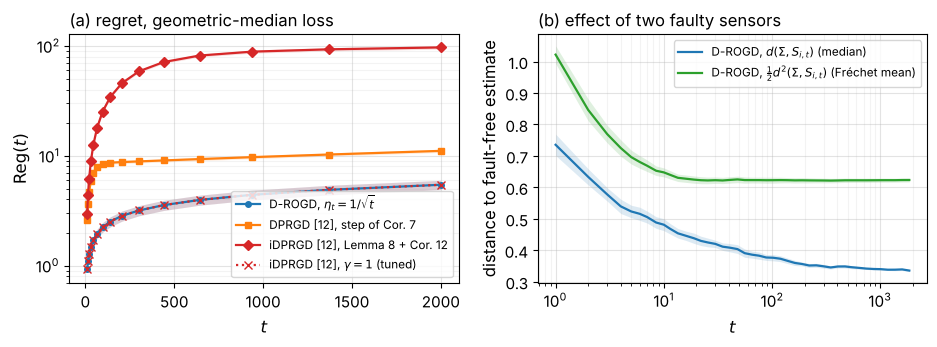

In [ ]:
# 5.2 Fig. R1 --------------------------------------------------------------------------
fig, (axa, axb) = plt.subplots(1, 2, figsize=FIGSIZE)

# (a) regret on the median losses, log scale
ck = runs[0]['median_ck']
for key, st in STYLE_A.items():
    m, s = band(stack(f'median_{key}_reg'))
    axa.plot(ck, m, label=LABELS[key], **st)
    axa.fill_between(ck, np.maximum(m - s, 1e-3), m + s, color=st['color'], alpha=0.15, lw=0)
axa.set_yscale('log')
axa.set_xlabel(r'$t$')
axa.set_ylabel(r'$\mathrm{Reg}(t)$')
axa.legend(loc='lower right')

# (b) distance of the D-ROGD estimate to the fault-free estimate, log time axis
for loss, color in STYLE_B.items():
    t = runs[0][f'{loss}_drogd_bin_t']
    m, s = band(stack(f'{loss}_drogd_to_clean'))
    axb.plot(t, m, color=color, lw=1.6, label=LABELS[loss])
    axb.fill_between(t, m - s, m + s, color=color, alpha=0.15, lw=0)
axb.set_xscale('log')
axb.set_xlabel(r'$t$')
axb.set_ylabel('distance to fault-free estimate')
axb.legend(loc='upper right')

for ax, title in zip((axa, axb), TITLES):
    ax.set_title(title, loc='left')
    ax.grid(True, which='major', alpha=0.35)
    ax.grid(True, which='minor', alpha=0.15)
fig.tight_layout()
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(FIG_DIR, f'fig_control_application.{ext}'), dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# 5.3 Numbers quoted in the response to the reviewers -------------------------------
lines = []


def note(s):
    print(s)
    lines.append(s)


T = ck[-1]
base = stack('median_drogd_reg')[:, -1]
for key in STYLE_A:
    v = stack(f'median_{key}_reg')[:, -1]
    note(f'median {key:13s} Reg(T)/sqrt(T) = {v.mean() / np.sqrt(T):.3f}   '
         f'ratio to D-ROGD = {np.mean(v / base):.2f}')
base = stack('mean_drogd_reg')[:, -1]
for key in ('drogd', 'cai12', 'cai12_tuned'):
    v = stack(f'mean_{key}_reg')[:, -1]
    note(f'mean   {key:13s} Reg(T)/(1+log T) = {v.mean() / (1 + np.log(T)):.3f}   '
         f'ratio to D-ROGD = {np.mean(v / base):.2f}')
for loss in ('median', 'mean'):
    note(f'{loss:6s} distance to fault-free estimate at T: '
         f'{stack(f"{loss}_drogd_to_clean")[:, -1].mean():.3f} '
         f'(batch comparator {stack(f"{loss}_xstar_to_clean").mean():.3f})')
with open(os.path.join(FIG_DIR, 'summary_sensor_network.txt'), 'w') as f:
    f.write('\n'.join(lines) + '\n')

median drogd         Reg(T)/sqrt(T) = 0.122   ratio to D-ROGD = 1.00
median dprgd_c7      Reg(T)/sqrt(T) = 0.248   ratio to D-ROGD = 2.14
median idprgd_c12    Reg(T)/sqrt(T) = 2.169   ratio to D-ROGD = 18.79
median idprgd_tuned  Reg(T)/sqrt(T) = 0.122   ratio to D-ROGD = 1.00
mean   drogd         Reg(T)/(1+log T) = 0.378   ratio to D-ROGD = 1.00
mean   cai12         Reg(T)/(1+log T) = 4.580   ratio to D-ROGD = 11.90
mean   cai12_tuned   Reg(T)/(1+log T) = 0.378   ratio to D-ROGD = 1.00
median distance to fault-free estimate at T: 0.336 (batch comparator 0.327)
mean   distance to fault-free estimate at T: 0.623 (batch comparator 0.624)
